In [2]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from patsy import dmatrix
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

#importing all of the libraries necessary for data handling, modeling, and to generating charts.
#turned off warning messages to make outputs look cleaner

In [4]:
df = pd.read_csv("data/Human_Resources.csv")
print("Shape:", df.shape)
df.head()

#read and load HR dataset

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


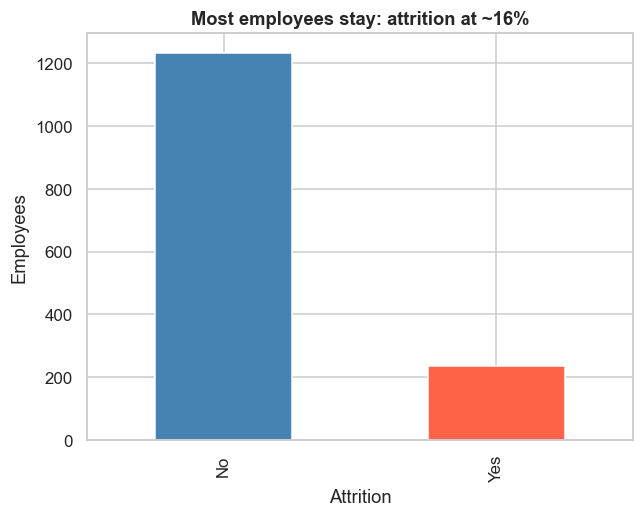

In [8]:
print(df["Attrition"].value_counts(normalize=True))

df["Attrition"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Most employees stay: attrition at ~16%")
plt.ylabel("Employees")
plt.show()

#comparing how many employees left vs. how many employees stayed: shows that around 16% left

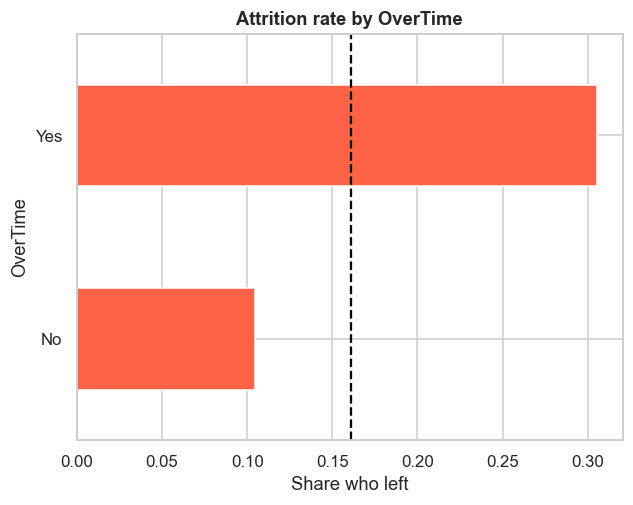

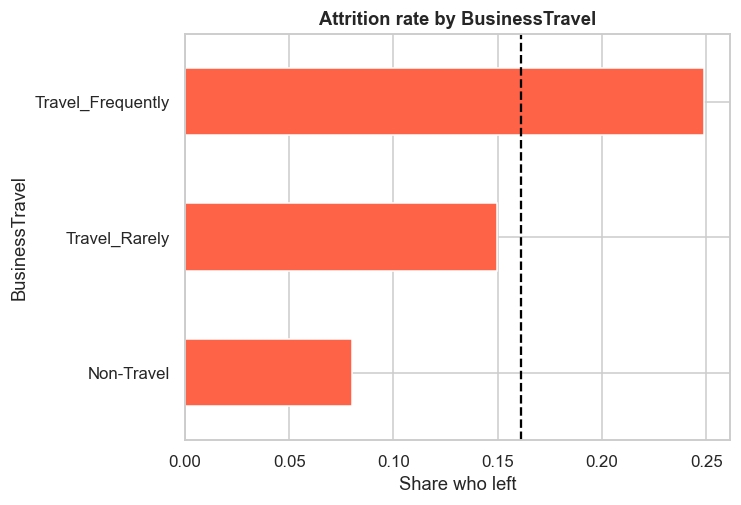

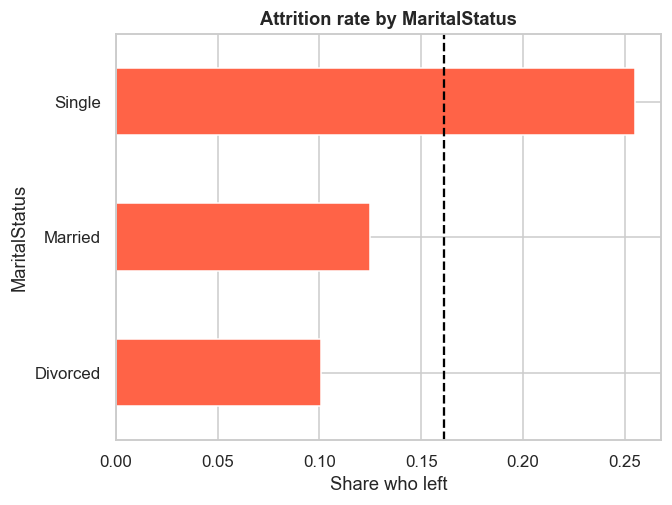

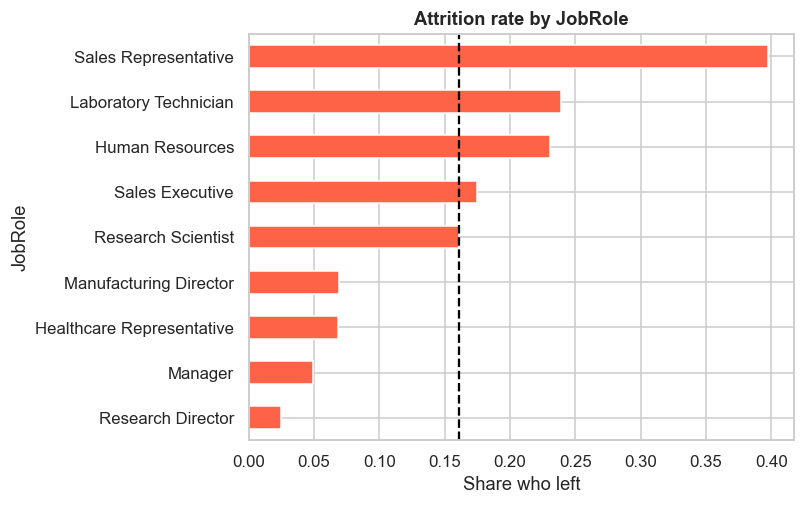

In [9]:
left = (df["Attrition"] == "Yes").astype(int)   # 1 = left, 0 = stayed
overall_rate = left.mean()

for col in ["OverTime", "BusinessTravel", "MaritalStatus", "JobRole"]:
    left.groupby(df[col]).mean().sort_values().plot(kind="barh", color="tomato")
    plt.axvline(overall_rate, color="black", linestyle="--")   # company average
    plt.title(f"Attrition rate by {col}")
    plt.xlabel("Share who left")
    plt.show()

#for each category, it shows the part of the employees that left and compares it to the company's
 #average (dashed line at ~16%)to conclude which groups are at a higher risk

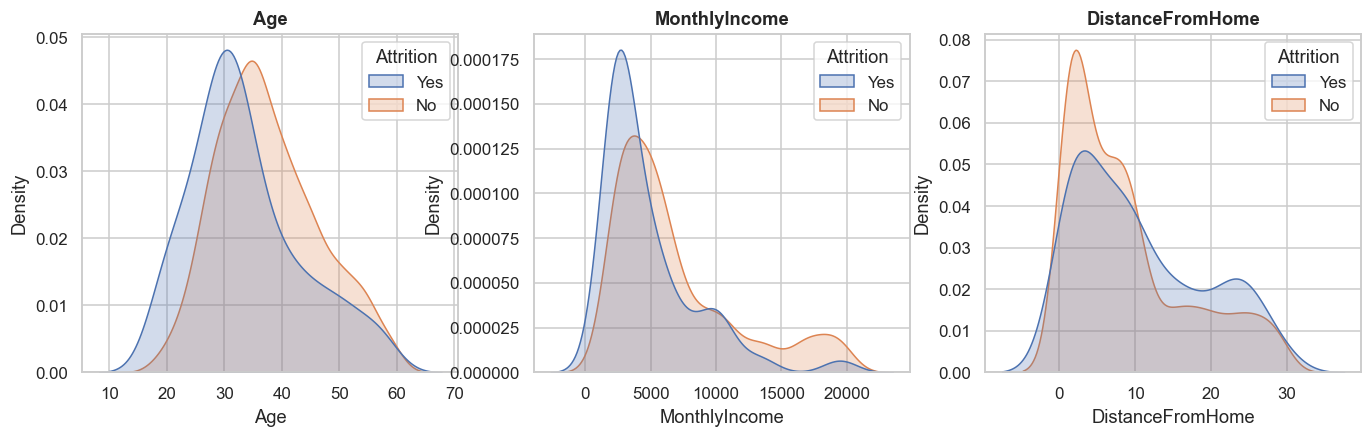

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "MonthlyIncome", "DistanceFromHome"]):
    sns.kdeplot(data=df, x=col, hue="Attrition", fill=True, common_norm=False, ax=ax)
    ax.set_title(col)
plt.show()

#histograms to compage age, income, and distance for employees who stayed vs. left

In [14]:
drop_cols = [c for c in df.columns if df[c].nunique() == 1] + ["EmployeeNumber"]

y = df["Attrition"]
X = pd.get_dummies(df.drop(columns=["Attrition"] + drop_cols), drop_first=True, dtype=float)

X_lr = X.drop(columns=[c for c in X.columns if c.startswith("Department_")])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
X_lr_train, X_lr_test = X_lr.loc[X_train.index], X_lr.loc[X_test.index]

print("Train:", X_train.shape, "| Test:", X_test.shape)

#cleaning data to drop irrelevant columns and then turning text columns into 0/1 columns
#splitting data 75% train/25% test

Train: (1102, 44) | Test: (368, 44)


In [16]:
def report(y_true, y_pred, name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=["No", "Yes"]).ravel()
    out = {
        "Model": name,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Precision": tp / (tp + fp),
        "Recall": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
    }
    print(pd.DataFrame({"Predicted No": [tn, fn], "Predicted Yes": [fp, tp]},
                       index=["Actual No", "Actual Yes"]))
    print()
    for k in ["Accuracy", "Precision", "Recall", "Specificity"]:
        print(f"{k:<12}{out[k]:.4f}")
    return out

results, p_yes, preds = [], {}, {}

#confusion matrix

In [19]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

lda_pred = lda.predict(X_test)
lda_prob = lda.predict_proba(X_test)
p_yes["Discriminant Analysis"] = lda_prob[:, list(lda.classes_).index("Yes")]
preds["Discriminant Analysis"] = lda_pred

results.append(report(y_test, lda_pred, "Discriminant Analysis"))

#discriminant analysis
 #training the first model on the training data so we can predict who levaes in the test data
 #it then saves each persons probability of leaving so i can compare models later

            Predicted No  Predicted Yes
Actual No            297             12
Actual Yes            36             23

Accuracy    0.8696
Precision   0.6571
Recall      0.3898
Specificity 0.9612


In [20]:
y_bin = (y == "No").astype(int)          # 1 = stays, 0 = leaves
y_bin_train = y_bin.loc[X_train.index]

X_lr_train_c = sm.add_constant(X_lr_train)
X_lr_test_c = sm.add_constant(X_lr_test, has_constant="add")
logit = sm.Logit(y_bin_train, X_lr_train_c).fit(disp=0, maxiter=200)

logit_p_no = logit.predict(X_lr_test_c)
logit_pred = np.where(logit_p_no < 0.5, "Yes", "No")
p_yes["Logistic Regression"] = 1 - logit_p_no.values
preds["Logistic Regression"] = logit_pred

results.append(report(y_test, logit_pred, "Logistic Regression"))

#logistic regression
 #predicting an employees chance of staying
 #"leaving" means whenever the chance is below 50%

            Predicted No  Predicted Yes
Actual No            297             12
Actual Yes            38             21

Accuracy    0.8641
Precision   0.6364
Recall      0.3559
Specificity 0.9612


In [21]:
age_spline = dmatrix("bs(Age, df=6) - 1", {"Age": df["Age"]}, return_type="dataframe")
age_spline.columns = [f"Age_spline{i + 1}" for i in range(age_spline.shape[1])]

X_spl = sm.add_constant(pd.concat([X_lr.drop(columns="Age"), age_spline], axis=1))
X_spl_train, X_spl_test = X_spl.loc[X_train.index], X_spl.loc[X_test.index]

logit_spl = sm.Logit(y_bin_train, X_spl_train).fit(disp=0, maxiter=200)

spl_p_no = logit_spl.predict(X_spl_test)
spl_pred = np.where(spl_p_no < 0.5, "Yes", "No")
p_yes["Logistic Regression with Splines"] = 1 - spl_p_no.values
preds["Logistic Regression with Splines"] = spl_pred

results.append(report(y_test, spl_pred, "Logistic Regression with Splines"))

#logistic regressiono + spline on age
 #same logistic model as before but the effect of age can bend

            Predicted No  Predicted Yes
Actual No            300              9
Actual Yes            37             22

Accuracy    0.8750
Precision   0.7097
Recall      0.3729
Specificity 0.9709


In [22]:
y_test_bin = (y_test == "Yes").astype(int)

comparison = pd.DataFrame(results).set_index("Model")
comparison["AUC"] = [roc_auc_score(y_test_bin, p_yes[m]) for m in comparison.index]
print(comparison.round(4))

print("\nNaive 'always No' accuracy:", round((y_test == "No").mean(), 4))
best_model = comparison["AUC"].idxmax()
print("Best model by AUC:", best_model)

#comparing both models

                                  Accuracy  Precision  Recall  Specificity     AUC
Model                                                                             
Discriminant Analysis               0.8696     0.6571  0.3898       0.9612  0.7986
Discriminant Analysis               0.8696     0.6571  0.3898       0.9612  0.7986
Logistic Regression                 0.8641     0.6364  0.3559       0.9612  0.8107
Logistic Regression with Splines    0.8750     0.7097  0.3729       0.9709  0.8223

Naive 'always No' accuracy: 0.8397
Best model by AUC: Logistic Regression with Splines


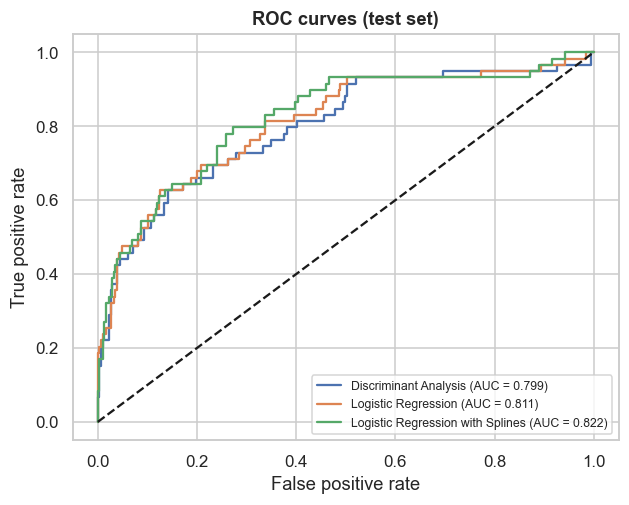

In [26]:
for m in comparison.index:
    fpr, tpr, _ = roc_curve(y_test_bin, p_yes[m])
    plt.plot(fpr, tpr, label=f"{m} (AUC = {comparison.loc[m, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (test set)")
plt.legend(loc="lower right", fontsize=8)
plt.show()

#roc curve
 #shows how well each model differntiates the leavers from the stayers
 #higher curve = better

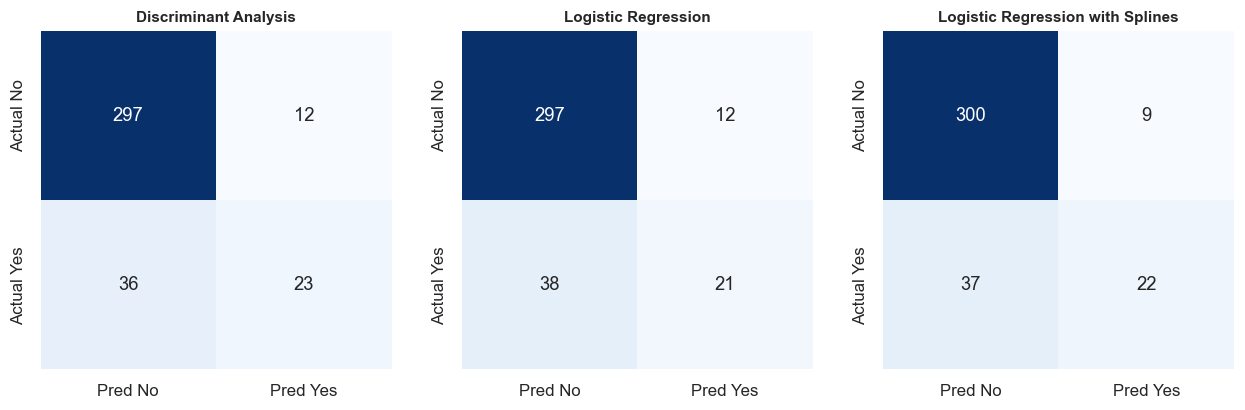

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, comparison.index):
    cm = confusion_matrix(y_test, preds[m], labels=["No", "Yes"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"])
    ax.set_title(m, fontsize=10)
plt.show()

#confustion matricies
 #each box counts correct/incorrect predictions 
 #bottom row shows the comparison between the actual number of people that left vs. 
    #how many the model caught/missed

In [28]:
TARGET_RECALL = 0.70

p_yes_train = 1 - logit.predict(X_lr_train_c).values
y_train_bin = (y_train == "Yes").astype(int)

prec, rec, thr = precision_recall_curve(y_train_bin, p_yes_train)
ok = rec[:-1] >= TARGET_RECALL
chosen = thr[ok][np.argmax(prec[:-1][ok])]
print(f"Chosen threshold: {chosen:.3f}")

tuned_pred = np.where(p_yes["Logistic Regression"] >= chosen, "Yes", "No")
tuned = report(y_test, tuned_pred, f"Logistic Regression (threshold {chosen:.2f})")

#only 16% of employees leave so the defualt of 50% does not flag anyone and misses most people that end up leaving
#by lowering the cutoff using the training data it catches more employees that leave
#then this is checked it on the test data where reecall rose by 8% from 36% to 54%

Chosen threshold: 0.276
            Predicted No  Predicted Yes
Actual No            278             31
Actual Yes            27             32

Accuracy    0.8424
Precision   0.5079
Recall      0.5424
Specificity 0.8997


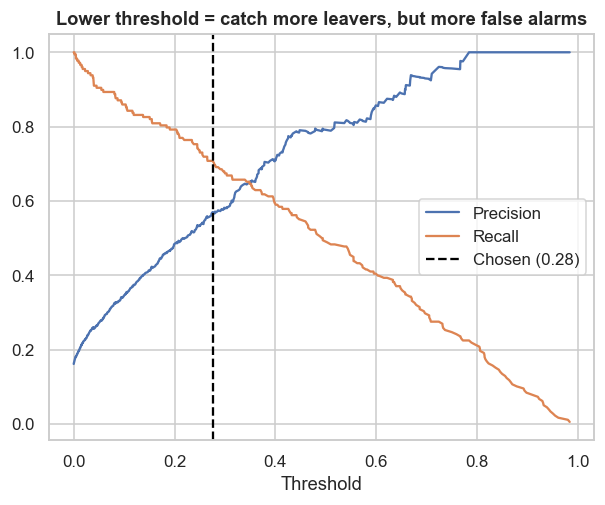

In [29]:
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(chosen, color="black", linestyle="--", label=f"Chosen ({chosen:.2f})")
plt.xlabel("Threshold")
plt.title("Lower threshold = catch more leavers, but more false alarms")
plt.legend()
plt.show()

#precision v. recall tradeoff
 #as cutoff drops, the amount of employees that end up leaving are caught, and precision goes down

In [30]:
ci = logit.conf_int()
odds = pd.DataFrame({
    "Odds ratio (leaving)": np.exp(-logit.params),
    "CI low": np.exp(-ci[1]),
    "CI high": np.exp(-ci[0]),
    "p-value": logit.pvalues,
}).drop(index="const")

print("Strongest risk factors (significant, odds ratio > 1):")
print(odds[(odds["p-value"] < 0.05) & (odds["Odds ratio (leaving)"] > 1)]
      .sort_values("Odds ratio (leaving)", ascending=False).head(10).round(3))

print("\nStrongest protective factors (significant, odds ratio < 1):")
print(odds[(odds["p-value"] < 0.05) & (odds["Odds ratio (leaving)"] < 1)]
      .sort_values("Odds ratio (leaving)").head(10).round(3))

#what drives attrition?
 #turned model coeffs into odds ratios
 #value above 1 = higher odds of leaving
 #value below 1 = lower odds of leaving
 #only keeping statistically significant ones

Strongest risk factors (significant, odds ratio > 1):
                                  Odds ratio (leaving)  CI low  CI high  p-value
JobRole_Sales Representative                    14.748   3.666   59.336    0.000
JobRole_Laboratory Technician                    8.546   2.503   29.186    0.001
BusinessTravel_Travel_Frequently                 7.414   2.849   19.298    0.000
OverTime_Yes                                     7.347   4.648   11.613    0.000
JobRole_Sales Executive                          4.246   1.345   13.402    0.014
BusinessTravel_Travel_Rarely                     2.795   1.162    6.724    0.022
MaritalStatus_Single                             2.428   1.088    5.418    0.030
NumCompaniesWorked                               1.224   1.117    1.340    0.000
YearsSinceLastPromotion                          1.201   1.087    1.326    0.000
DistanceFromHome                                 1.051   1.025    1.077    0.000

Strongest protective factors (significant, odds ratio 

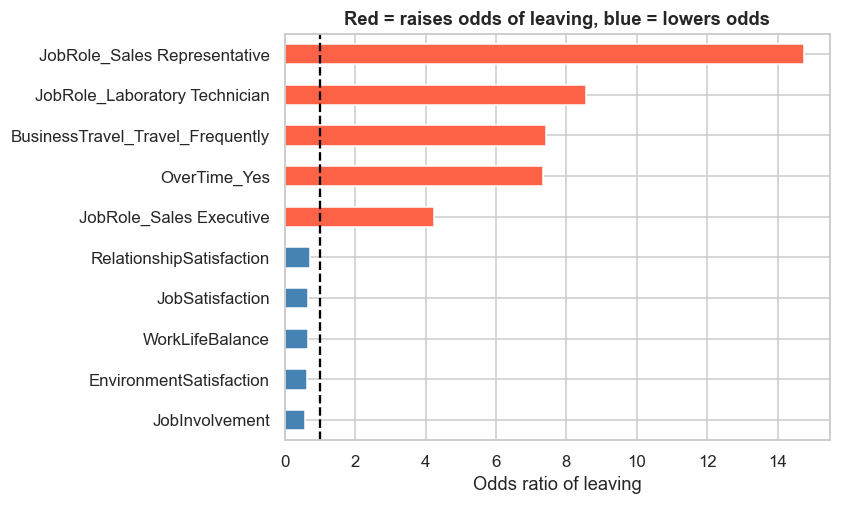

In [31]:
sig = odds[odds["p-value"] < 0.05]["Odds ratio (leaving)"].sort_values()
top = pd.concat([sig.head(5), sig.tail(5)])      # 5 most protective + 5 biggest risks

top.plot(kind="barh", color=["steelblue" if v < 1 else "tomato" for v in top])
plt.axvline(1, color="black", linestyle="--")
plt.xlabel("Odds ratio of leaving")
plt.title("Red = raises odds of leaving, blue = lowers odds")
plt.show()

#shows biggest risk factors in red
#shows biggest protective factors in blue
#dashed line at 1 = no effect

In [32]:
'''
In this, I compared 3 models to predict attrition. In this, I found that accuracy was misleading as
most people stay and htis lowered the decisin to catch more employees that end up leaving. I also used
odds ratios to show that overtime and frequent travel were the biggest drivers
'''

'\nIn this, I compared 3 models to predict attrition. In this, I found that accuracy was misleading as\nmost people stay and htis lowered the decisin to catch more employees that end up leaving. I also used\nodds ratios to show that overtime and frequent travel were the biggest drivers\n'